# **Maestría en Inteligencia Artificial Aplicada**

## **Curso: Inteligencia Artificial y Aprendizaje Automático**

**Tecnológico de Monterrey**

**Prof Luis Eduardo Falcón Morales**

### **Actividad de Modelos basados en Árboles**

* **Nombre:** Brandon Bernal Torres

* **Matrícula:** A01383238


# **Introducción: Auditoría de modelos de riesgo crediticio basados en Árboles**



### **Contexto del problema:**

* Una startup de tecnología financiera (fintech) llamada CrediNova busca fortalecer su proceso de evaluación de riesgo para créditos de consumo. Actualmente, la empresa recibe miles de solicitudes cada mes y desea anticipar cuáles clientes podrían incumplir sus obligaciones financieras durante los próximos 90 días.

* Dichos clientes ya tienen una relación vigente con la institución, con la cual ya poseen uno o más productos financieros activos. Se desea predecir, al momento de la evaluación (para otorgar o revisar un crédito), cuáles de dichos clientes caerán en incumplimiento de algunos de sus pagos durante los siguientes 90 días.

* Un analista junior del área de ciencia de datos bajo su propia iniciativa desarrolló la solución que se encuentra en este cuaderno de Jupyter, la cual está basada en modelos de árboles. Se dio a la tarea de conjuntar la información histórica con diversas áreas de la empresa y generar la base de datos que se encuentra en el archivo "fintech_default_risk.csv". Dicho archivo lo encuentras en Canvas.  

* Los resultados que se obtienen al ejecutar el código se ven bastante prometedores, tan es así, que el CEO desea autorizar su despliegue a producción lo antes posible. Sin embargo, la dirección de riesgos desea realizar antes una última validación de la propuesta. Siendo tú un científico de datos senior, te encargan realizar una auditoría forense de este cuaderno.  

* En particular, se espera que cumplas con los siguientes objetivos:

  * Puedes modificar el cuaderno (celdas de texto y código) tanto como lo consideres necesario, salvo donde se te indique.

  * Identificar y documentar al menos 6 errores conceptuales o metodológicos en la propuesta actual.
  
  * Detectar posibles fuentes de fuga de información (data leakage) tanto en los datos como en el proceso de ajuste y entrenamiento de los modelos.

  * Justificar el uso de la métrica, y en su caso, evaluar la pertinencia de proponer y usar otras métricas.

  * Identificar evidencia de sub o sobreentrenamiento con respecto a la métrica en cuestión.

  * Analizar el impacto de la selección del umbral de clasificación sobre los resultados del negocio.

  * Decidir cuál de los 3 modelos de árboles consideras el más adecuado para desplegar en producción.

  * Identificar los 3 o 4 factores más importantes del mejor modelo obtenido. Explicar sus significados en el contexto de negocio.

  * Realizar un reporte del resultado de la auditoría forense comprensible para los tomadores de decisiones. En particular, indicar si el modelo se puede desplegar en producción como lo propone el analista junior, o cuál serían en dado caso las recomendaciones.

  * Reportar las herramientas de IA generativa (LLMs) utilizadas como apoyo para la auditoría.
  

### **Descripción del negocio:**

* Cada vez que una solicitud de crédito es aprobada:
   * Si el cliente paga correctamente, la empresa obtiene una utilidad neta estimada de $100 USD.

   * Si el cliente entra en incumplimiento, la empresa enfrenta una pérdida promedio estimada de $500 USD.

* Por este motivo, el objetivo no consiste únicamente en maximizar métricas estadísticas, sino en maximizar el valor económico esperado para la organización. Por ello, como parte del análisis, también deberás estimar:
   * La utilidad esperada utilizando el umbral estándar de clasificación (0.5).

   * La utilidad esperada utilizando un umbral optimizado.
   
   * El impacto económico estimado por cada 10,000 solicitudes evaluadas.

# **Cargando y conociendo la información**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from imblearn.over_sampling import SMOTE

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import shap


RANDOM_STATE = 11   # No modificar el valor de esta semilla.
                    # Siempre que aparezca esta semilla, seguirla utilizando,
                    # inclusive con modelos o cualquier otra función o método.

In [2]:
# Cargamos los datos y obtenemos alguna información básica:

df = pd.read_csv('fintech_default_risk.csv')

print("Dimensión:", df.shape)
print("-"*25)
print('Variables involucradas:')
print(df.head(3).T)

print("\n")
print("-"*25)
print("Distribución objetivo:")
print(df["default_90d"].value_counts(normalize=True))


Dimensión: (5000, 14)
-------------------------
Variables involucradas:
                                         0             1             2
edad                             46.000000     37.000000     48.000000
ingreso_mensual               34959.928315   8659.826698  11502.487602
antiguedad_laboral_meses        296.000000      6.000000    166.000000
score_crediticio                659.093869    728.456721    636.261824
utilizacion_credito               0.410414      0.882132      0.408709
atrasos_12m                       3.000000      1.000000      1.000000
consultas_buro_6m                 5.000000      2.000000      3.000000
num_productos                     7.000000      3.000000      1.000000
limite_credito               209105.311645  44070.504292  42132.236007
deuda_total                   77661.271706  42105.837892  15409.496357
relacion_deuda_ingreso            2.221373      4.861642      1.339550
dias_max_atraso_30d_despues       7.000000      4.000000      3.000000
clien

In [3]:
# Definimos nuestras variables de entrada y la objetivo:

target = "default_90d"

X = df.drop(columns=[target])
y = df[target]

In [4]:
# Debido al desbalanceo de clases, aplicaremos una técnica de balanceo de clases.

smote = SMOTE(random_state=RANDOM_STATE   # semilla
              )

X_res, y_res = smote.fit_resample(X, y) # Balanceamos las clases con valores predeterminados de SMOTE.

X_train, X_test, y_train, y_test = train_test_split(
    X_res,
    y_res,
    test_size=0.30,  # Usemos una partición 70%-30%, pero podría ajustarse, en dado caso.
    random_state=RANDOM_STATE  # semilla
)

# **Configuración y Entrenamiento de los Modelos**

In [5]:
# --- Modelo 1: Árbol de decisión ---
dt = DecisionTreeClassifier(random_state=RANDOM_STATE  # semilla
                            )
dt.fit(X_train, y_train)

# --- Modelo 2: Random Forest ---
rf = RandomForestClassifier(random_state=RANDOM_STATE  # semilla
                            )
rf.fit(X_train, y_train)

# --- Modelo 3: XGBoost ---
xgb = XGBClassifier(eval_metric='logloss',   # métrica caso binario
                    random_state=RANDOM_STATE  # semilla
                    )
xgb.fit(X_train, y_train)


# Obtenemos los desempeños, verificando que no estén sobreentrenados,
# ni subentrenados:
modelos = {
    "Árbol de Decisión": dt,
    "Random Forest": rf,
    "XGBoost": xgb
}

y_probs = []   # Guardemos las probabilidades para uso posterior:
               # 0:DT, 1:RF, 2:XGBoost
print("Desempeño de los modelos:")
print("+"*25)
for nombre, modelo in modelos.items():

    y_pred_train = modelo.predict(X_train)
    y_pred_test = modelo.predict(X_test)
    y_probs.append(modelo.predict_proba(X_test)[:,1])

    # Verificando en los conjuntos de Train y Test:
    acc_train = accuracy_score(y_train, y_pred_train)
    acc_test = accuracy_score(y_test, y_pred_test)

    print(f"{nombre}:")

    print(f"Train: {acc_train:.4f}")
    print(f"Test: {acc_test:.4f}")
    print("+"*20)

Desempeño de los modelos:
+++++++++++++++++++++++++
Árbol de Decisión:
Train: 1.0000
Test: 1.0000
++++++++++++++++++++
Random Forest:
Train: 1.0000
Test: 1.0000
++++++++++++++++++++
XGBoost:
Train: 1.0000
Test: 1.0000
++++++++++++++++++++


# **Importancia e Interpretabilidad de los Factores o Características:**

**Los tres modelos obtienen la misma accuracy en esta ejecución. Se conservan las importancias del Árbol de Decisión y Random Forest como referencia y el análisis SHAP de XGBoost, que es el modelo utilizado por el código para el análisis económico. La igualdad de accuracy no demuestra que los modelos sean igualmente adecuados para producción.**

In [6]:
# Modelo de Árbol de Decisión (decision tree-dt):

importancias = dt.feature_importances_

# Creamos el DataFrame para ordenarlas y visualizarlas mejor:
df_importancias = pd.DataFrame({
    'Característica:': X.columns,
    'Importancia': importancias
}).sort_values(by='Importancia', ascending=False)

print(df_importancias)

                Característica:  Importancia
11  dias_max_atraso_30d_despues          1.0
1               ingreso_mensual          0.0
2      antiguedad_laboral_meses          0.0
3              score_crediticio          0.0
0                          edad          0.0
4           utilizacion_credito          0.0
5                   atrasos_12m          0.0
7                 num_productos          0.0
6             consultas_buro_6m          0.0
8                limite_credito          0.0
9                   deuda_total          0.0
10       relacion_deuda_ingreso          0.0
12              cliente_premium          0.0


In [7]:
# Modelo Bosque Aleatorio (Random Forest-rf):

importancias = pd.DataFrame({
    "Variable": X_train.columns,
    "Importancia": rf.feature_importances_
})

importancias = importancias.sort_values(
    "Importancia",
    ascending=False
)

print(importancias.head(10))

                       Variable  Importancia
11  dias_max_atraso_30d_despues     0.822857
4           utilizacion_credito     0.058264
3              score_crediticio     0.025473
10       relacion_deuda_ingreso     0.023019
6             consultas_buro_6m     0.018116
12              cliente_premium     0.011584
7                 num_productos     0.008276
9                   deuda_total     0.007900
2      antiguedad_laboral_meses     0.006443
0                          edad     0.005921


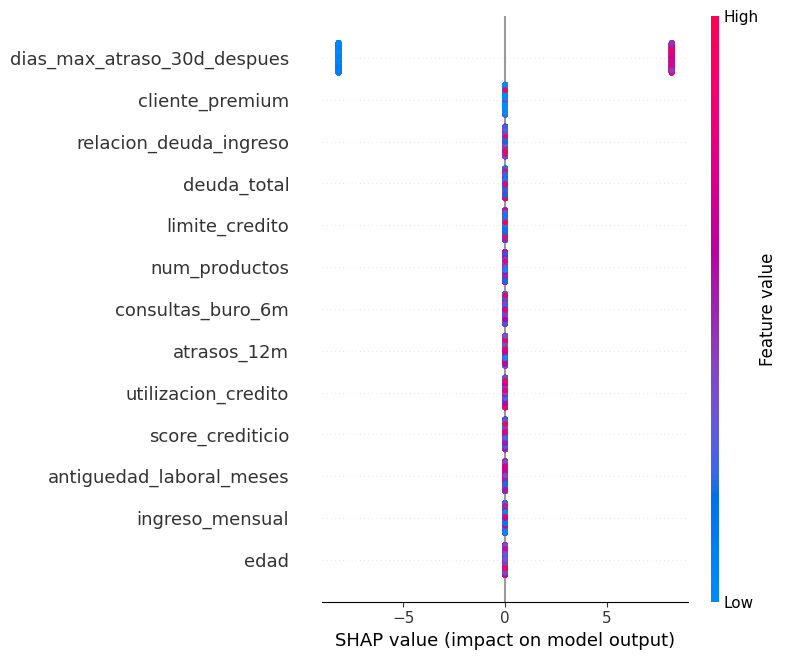

In [8]:
# Modelo XGBoost:

explainer = shap.TreeExplainer(xgb)

shap_values = explainer.shap_values(X_test)

shap.summary_plot(
    shap_values,
    X_test
)

## **Seleccionemos y analicemos un cliente en Particular:**

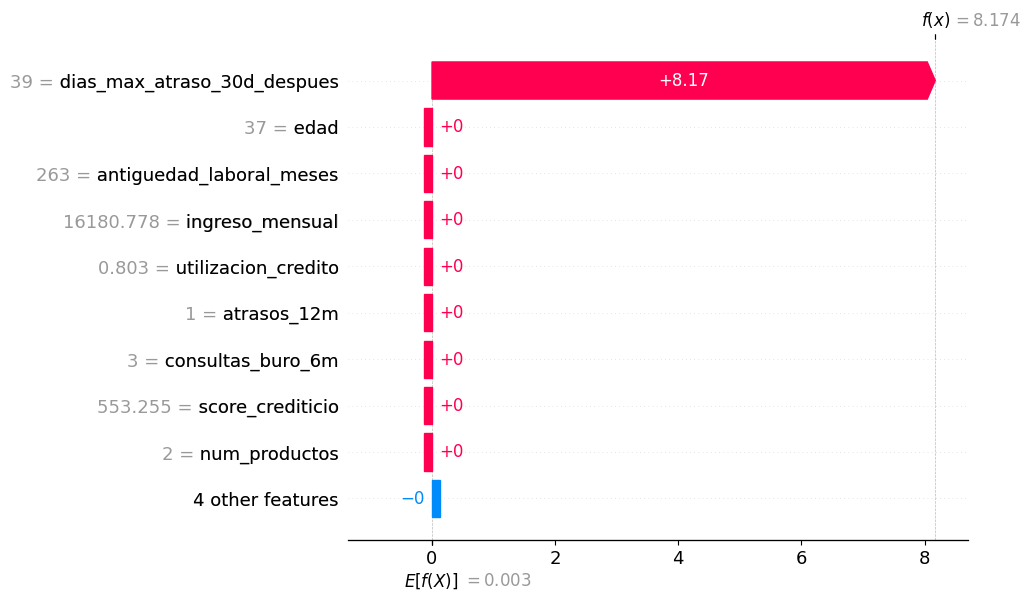

In [9]:
# Analicemos a un cliente en particular con XGBoost:

cliente = X_test.iloc[[11]]
shap_values_cliente = explainer.shap_values(cliente)

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values_cliente[0],
        base_values=explainer.expected_value,
        data=cliente.iloc[0],
        feature_names=cliente.columns
    )
)

**Interpretación del gráfico:**

* El factor de riesgo principal (máximo días de atraso en alguno de sus pagos durante los 30 días siguientes a la evaluación) termina siendo determinante, lo que resulta en una predicción de riesgo final (en escala log-odds) de  f(x)=8.174  (muy por encima del promedio E[f(X)]=0.003). Así, si el umbral de aprobación fuera el estándar de 0.50, este cliente sería rechazado.

# **Análisis desde la perspectiva del negocio:**

In [10]:
GANANCIA_BUENO = 100
PERDIDA_DEFAULT = -500


In [11]:
# Función de utilidad:

# Considerando el umbral estándar:
threshold = 0.5

def utilidad(y_true, y_prob, threshold):

    aprobar = y_prob < threshold

    utilidad_total = 0

    for real, aprobado in zip(y_true, aprobar):

        if aprobado:

            if real == 0:
                utilidad_total += 100

            else:
                utilidad_total -= 500

    return utilidad_total



# Mejor modelo encontrado:
y_probs_mejor_modelo = y_probs[2]   # XGBoost

utilidad_05 = utilidad(
    y_test,
    y_probs_mejor_modelo,
    threshold=0.5
)

print("Mayor Utilidad (USD) con umbral 0.5:")
print(utilidad_05)

Mayor Utilidad (USD) con umbral 0.5:
132700


Mejor umbral: 0.01
Mayor Utilidad (USD): 132700


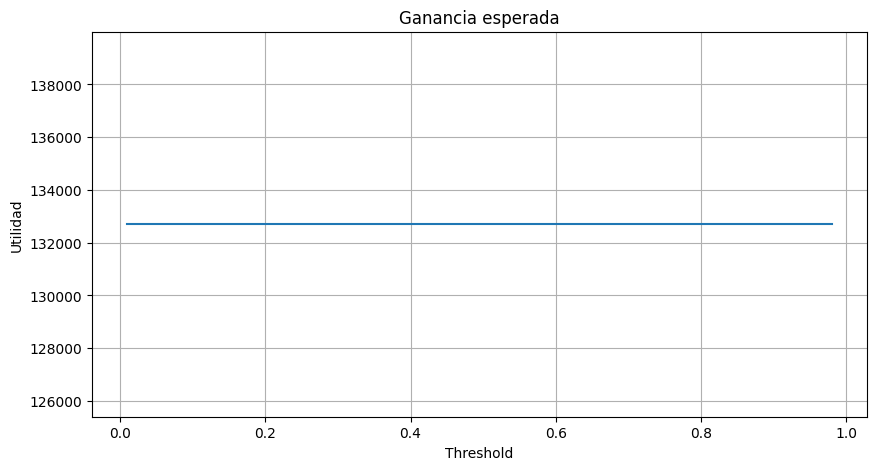

In [12]:
# Ajustando para buscar el mejor umbral óptimo:

thresholds = np.arange(
    0.01,
    0.99,
    0.01
)

utilidades = []

for th in thresholds:

    u = utilidad(
        y_test,
        y_probs_mejor_modelo,
        threshold=th
    )

    utilidades.append(u)

best_idx = np.argmax(utilidades)

best_threshold = thresholds[best_idx]

best_profit = utilidades[best_idx]

print('Mejor umbral:',best_threshold)
print('Mayor Utilidad (USD):',best_profit)



# Grafiquemos Umbral vs Utilidad:

plt.figure(figsize=(10,5))

plt.plot(
    thresholds,
    utilidades
)

plt.xlabel("Threshold")
plt.ylabel("Utilidad")
plt.title("Ganancia esperada")
plt.grid()

plt.show()

In [13]:
# Calculamos ahora la utilidad por cada 10,000 solicitudes:


def utilidad_por_10000(y_true, y_prob, threshold):

    aprobados = y_prob < threshold

    utilidad = 0
    total_aprobados = 0

    for real, aprobado in zip(y_true, aprobados):

        if aprobado:

            total_aprobados += 1

            if real == 0:
                utilidad += GANANCIA_BUENO

            else:
                utilidad += PERDIDA_DEFAULT

    # Escalamos a 10,000 solicitudes:
    utilidad_escalada = utilidad * (
        10_000 / len(y_true)
    )

    return utilidad_escalada



In [14]:
profit_default = utilidad_por_10000(
    y_test,
    y_probs_mejor_modelo,
    threshold=0.50
)

profit_optimal = utilidad_por_10000(
    y_test,
    y_probs_mejor_modelo,
    threshold=best_threshold
)

delta = profit_optimal - profit_default

incremento_pct = (
    delta /
    abs(profit_default)
) * 100

print(f"Threshold 0.50 : ${profit_default:,.0f}")
print(f"Threshold óptimo : ${profit_optimal:,.0f}")
print(f"Diferencia : ${delta:,.0f}")
print(f"Incremento : {incremento_pct:.1f}%")

Threshold 0.50 : $500,944
Threshold óptimo : $500,944
Diferencia : $0
Incremento : 0.0%


## **Matriz de Confusión**



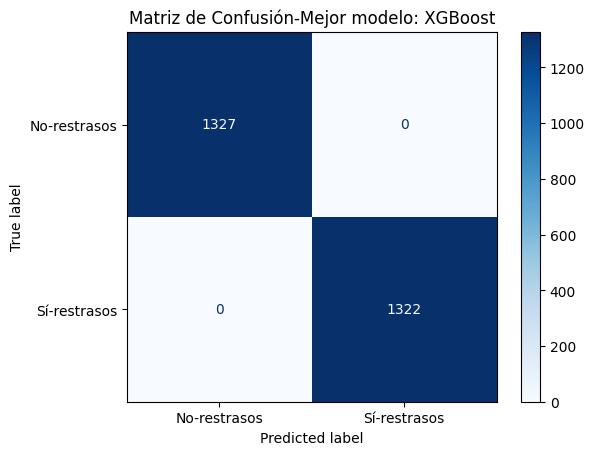

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay

class_names = ["No-restrasos", "Sí-restrasos"]
y_pred = modelo.predict(X_test)

disp = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=class_names, cmap=plt.cm.Blues
)
plt.title(f"Matriz de Confusión-Mejor modelo: {nombre}")
plt.show()

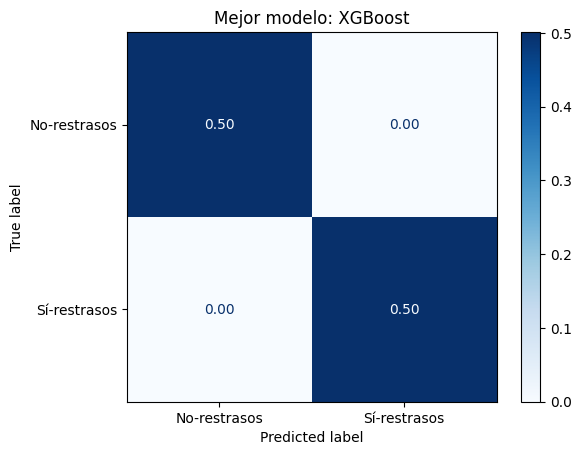

In [16]:
# O bien en su forma de proporciones:
disp = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=class_names,
    cmap=plt.cm.Blues,
    normalize='all',  # Normalizando con respecto al total de datos.
    values_format='.2f' # Total de decimales desplegadas.
)
plt.title(f"Mejor modelo: {nombre}")
plt.show()

# **Conclusiones particulares:**



**Incluye un reporte de los resultados obtenidos dirigido al CEO de la fintech con las sugerencias y conclusiones en relación a cuál modelo desplegar.**

### +++++++++++ Inicia sección de Conclusiones Particulares ++++++++++++++++

**Reporte al CEO de CrediNova**

No recomiendo desplegar ninguno de los tres modelos en su estado actual. Aunque sus resultados aparentan ser perfectos, la auditoría del código base identifica fuga de información y una evaluación que no representa las solicitudes reales. Los resultados siguientes corresponden a la ejecución del código original, con semilla 11; las correcciones se presentan como propuestas y no se aplicaron a sus celdas de código.

**Resultados de los modelos.** La base original contiene 5,000 registros y 11.72% de incumplimientos. El código aplica SMOTE antes de separar y genera 8,828 registros balanceados. Después utiliza 6,179 para entrenamiento y 2,649 para prueba; en prueba hay 1,327 clientes sin incumplimiento y 1,322 con incumplimiento.

| Modelo | Accuracy en entrenamiento | Accuracy en prueba |
|---|---:|---:|
| Árbol de Decisión | 1.0000 | 1.0000 |
| Random Forest | 1.0000 | 1.0000 |
| XGBoost | 1.0000 | 1.0000 |

No se observa una brecha de accuracy entre entrenamiento y prueba, pero esto no permite descartar sobreentrenamiento ni demostrar generalización: ambos conjuntos incluyen información futura y proceden del remuestreo aplicado a toda la base. Tampoco hay evidencia visible de subentrenamiento bajo esta evaluación contaminada. El código no incorpora validación cruzada, búsqueda de complejidad ni curvas de aprendizaje; por tanto, no permite establecer una configuración adecuada frente a sub/sobreentrenamiento.

**Errores metodológicos y correcciones propuestas.**

| Error identificado en el código base | Impacto técnico y de negocio | Corrección propuesta |
|---|---|---|
| Incluir `dias_max_atraso_30d_despues` | Usa información futura y produce una precisión que no puede reproducirse al tomar la decisión real | Excluirla y verificar la disponibilidad temporal de todos los predictores |
| Aplicar SMOTE antes de separar | La generación de vecinos sintéticos usa información de toda la muestra y puede vincular entrenamiento y prueba, haciendo optimista la evaluación | Separar primero y aplicar cualquier remuestreo solo dentro del entrenamiento de cada fold |
| Evaluar sobre la población balanceada por SMOTE | Cambia la prevalencia respecto al 11.72% original y distorsiona precisión, probabilidades y utilidad proyectada | Mantener validación y prueba originales, sin datos sintéticos |
| Usar SMOTE predeterminado con binarias y conteos | La interpolación puede producir valores sin sentido de negocio; la distancia también depende de la escala de las variables | Revisar las restricciones de las variables y justificar si se necesita remuestreo y qué técnica sería válida |
| No estratificar el split | No asegura proporciones comparables de incumplimiento en cada partición | Usar estratificación; agregar separación temporal o por cliente cuando existan fechas e identificadores |
| Usar accuracy como único criterio de desempeño | No refleja el costo asimétrico de los errores ni la detección de incumplimientos; en la base original predecir siempre no incumplimiento alcanzaría 88.28% de accuracy | Comparar precisión, recall, F1, AP, ROC-AUC, calibración y utilidad económica con datos independientes |
| No ajustar ni validar la complejidad de los modelos | Un buen ajuste contaminado puede ocultar memorización y generar pérdidas al cambiar la población | Regularizar y comparar entrenamiento con validación cruzada; reservar una prueba final independiente |
| Elegir XGBoost con `y_probs[2]` | La elección está fijada en el código, sin evidencia de superioridad estadística o económica frente a los otros dos | Seleccionar explícitamente el modelo con criterios de validación y negocio |
| Buscar el umbral con `y_test` | Reutiliza la prueba para ajustar la política y sobreestima su desempeño fuera de muestra | Optimizar el umbral en validación y evaluar una sola vez en prueba |
| No comprobar calibración ni corregir el cambio de prevalencia | Las probabilidades pueden no representar el riesgo real y conducir a decisiones económicas inadecuadas | Evaluar y, si procede, calibrar con datos que conserven la prevalencia real |
| Usar `modelo` y `nombre` residuales del bucle en la matriz | La matriz corresponde al último modelo recorrido; puede dejar de representar al seleccionado si cambia el orden. Además usa `predict`, no `best_threshold` | Referenciar explícitamente al elegido y aplicar el umbral recomendado al construir la matriz |

**Interpretabilidad y factores.** El Árbol de Decisión asigna importancia 1.0 a la variable futura y cero a las demás. En XGBoost, SHAP también identifica únicamente `dias_max_atraso_30d_despues` con contribución distinta de cero. Por tanto, no hay evidencia para afirmar que otros tres factores sean relevantes en el XGBoost de esta ejecución.

Como referencia, los cuatro factores principales del Random Forest que muestra el código son:

| Factor | Importancia por impureza | Significado de negocio |
|---|---:|---|
| `dias_max_atraso_30d_despues` | 0.8229 | Máximo atraso observado después de la evaluación; es una fuga temporal y no es utilizable al decidir |
| `utilizacion_credito` | 0.0583 | Fracción utilizada de las líneas de crédito; describe presión sobre el crédito disponible |
| `score_crediticio` | 0.0255 | Resumen del historial crediticio; según el diccionario, valores altos indican menor riesgo histórico |
| `relacion_deuda_ingreso` | 0.0230 | Relación entre deuda vigente e ingreso mensual; describe apalancamiento |

Estas importancias corresponden al bosque contaminado y no demuestran que conservarán su orden después de retirar la fuga. Tampoco establecen causalidad ni, por sí solas, la dirección del efecto. Para identificar tres o cuatro factores válidos del mejor modelo utilizable se necesita repetir la comparación con predictores disponibles al momento de evaluar.

**Impacto económico del código base.** XGBoost obtiene una utilidad de **USD 132,700** con umbral 0.50. La búsqueda devuelve **0.01** y una utilidad de **USD 132,700**. No hay mejora económica: ambos umbrales producen las mismas decisiones en esta ejecución. La búsqueda usa `np.argmax`, de modo que selecciona el primer máximo de la rejilla; no demuestra que 0.01 sea un óptimo único o estable.

| Política evaluada por el código | Utilidad en prueba (USD) | Proyección por 10,000 solicitudes (USD) |
|---|---:|---:|
| Umbral 0.50 | 132,700 | 500,943.75 |
| Umbral seleccionado 0.01 | 132,700 | 500,943.75 |
| Diferencia | 0 | 0 |

El incremento es **0.0%**. La matriz del código, construida con la decisión estándar de XGBoost, muestra 1,327 buenos clientes aprobados, 1,322 incumplidos rechazados y cero errores. Así, la utilidad es `1,327 × 100 = 132,700 USD`. Esa matriz no aplica expresamente el umbral optimizado, aunque en esta ejecución ambas políticas coinciden.

La proyección de aproximadamente USD 500,944 por 10,000 no es una estimación confiable del beneficio real: deriva de una muestra sintética balanceada, una variable futura y una selección de umbral sobre prueba. El código tampoco estima incertidumbre. Para probabilidades calibradas y los costos proporcionados, aprobar tendría valor esperado `100(1-p) - 500p`; el umbral teórico sería `p < 1/6`. Es una referencia económica, no un umbral validado o aplicado por este código.

**Recomendación.** El código usa XGBoost para la parte económica, pero no demuestra que sea superior a los otros dos modelos. No autorizaría el despliegue de ninguno con estos resultados. Recomiendo retirar la información futura, separar antes de ajustar, conservar la prevalencia en evaluación, validar complejidad y probabilidades, seleccionar modelo y umbral en validación y confirmar el desempeño con una prueba independiente. El CSV no incluye fecha ni identificador de cliente, por lo que también deben obtenerse esos datos para revisar independencia y estabilidad temporal. La decisión de producción debe depender de esa nueva evidencia, no del 100% de accuracy actual.

### +++++++++++ Termina sección de conclusiones particulares ++++++++++++++

# **Conclusiones**

Incluye todos los comentarios y conclusiones de esta actividad. En particular, responde sobre los siguientes puntos:

* Indica en qué casos el uso de LLMs fue de mayor provecho.
* En cuáles casos tu intervención como experto en combinación con los LLM fue importante para alcanzar con los objetivos propuestos.


### +++++++++++ Inicia sección de Conclusiones Finales ++++++++++++++++

La ejecución del código base produce accuracy de 1.0000 en entrenamiento y prueba para Árbol de Decisión, Random Forest y XGBoost. Estos valores no prueban que los modelos generalicen, porque la variable de atrasos posteriores anticipa información que no existe al decidir y SMOTE se aplica antes de la separación. No puede concluirse que los modelos estén libres de sobreentrenamiento únicamente porque no hay brecha de accuracy.

XGBoost es el modelo que el código elige para la utilidad, sin una comparación que justifique su superioridad. Con umbral 0.50 obtiene USD 132,700 y con el umbral seleccionado 0.01 obtiene la misma cantidad. La proyección por 10,000 es aproximadamente USD 500,944 en ambos casos y el incremento es cero. Estas cifras describen la muestra utilizada por el notebook; no constituyen una promesa de rentabilidad sobre solicitudes reales.

La interpretación SHAP confirma que XGBoost depende de la variable futura. Las importancias del Random Forest permiten describir otros factores como utilización de crédito, score y relación deuda/ingreso, pero no validarlos como factores de un sistema listo para producción. Se requiere una nueva evaluación sin fuga antes de elegir un modelo desplegable.

**Uso de LLMs.** Se utilizó ChatGPT/Codex de OpenAI como apoyo para revisar el código base, identificar errores metodológicos y redactar el reporte de auditoría. Fue especialmente útil para relacionar la fuga temporal, SMOTE antes del split y la búsqueda del umbral sobre prueba con sus consecuencias técnicas y económicas.

### +++++++++++ Termina sección de conclusiones finales ++++++++++++++

# **<<< Fin de la Actividad de la Semana - Modelos de Árboles >>>**